In [1]:

import re
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
from IPython.display import display
from datasets import load_dataset
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory

nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)
nltk.download('stopwords', quiet=True)

C:\Users\ASUS TUF GAMING\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


True

In [2]:
# 1. Memuat dataset dari Hugging Face
dataset = load_dataset("dipawidia/ecommerce-product-reviews-sentiment")
df = pd.DataFrame(dataset['train'])

# Menampilkan 5 baris awal untuk memastikan data berhasil dimuat
display(df.head())

,review,translate,sentimen
0,Suara dan mic puas. Hanya saya pesan yg nyala ...,sound and mic satisfied. I only ordered the on...,0
1,Good. Mudah-mudahan awet. Makasih,good. hopefully durable. Thanks,1
2,"kondisi dus robek2, tolong di perhatikan lagi","the condition of the box is torn, please pay a...",0
3,Kualitas produk baik. Harga terjangkau dan pen...,product quality is good. affordable prices and...,0
4,"Overall bagus, tombol berfungsi semuanya, tapi...","overall is good, the buttons all work, but the...",0


=== INFORMASI DATASET ===
Jumlah Baris (Data) : 11606
Jumlah Kolom        : 3
Nama Kolom          : ['review', 'translate', 'sentimen']

=== CEK TIPE DATA & MISSING VALUES ===
review       0
translate    0
sentimen     0
dtype: int64

=== DISTRIBUSI LABEL SENTIMEN ===


,Jumlah Data,Persentase (%)
sentimen,,
0,5803,50.0
1,5803,50.0


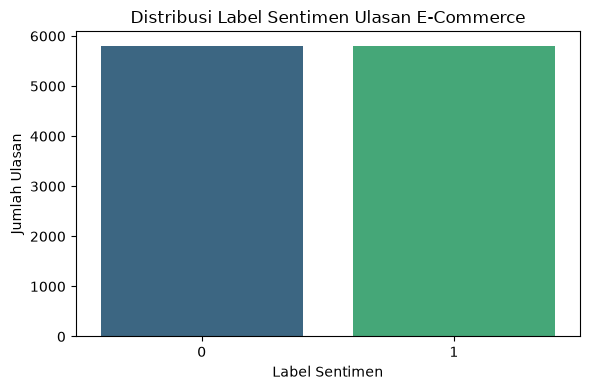

In [3]:
# 2. Informasi jumlah data, kolom, dan distribusi label sentimen
print("=== INFORMASI DATASET ===")
print(f"Jumlah Baris (Data) : {df.shape[0]}")
print(f"Jumlah Kolom        : {df.shape[1]}")
print(f"Nama Kolom          : {df.columns.tolist()}\n")

print("=== CEK TIPE DATA & MISSING VALUES ===")
print(df.isnull().sum())

print("\n=== DISTRIBUSI LABEL SENTIMEN ===")
distribusi_sentimen = pd.DataFrame({
    'Jumlah Data': df['sentimen'].value_counts(),
    'Persentase (%)': (df['sentimen'].value_counts(normalize=True) * 100).round(2)
})
display(distribusi_sentimen)

# Grafik distribusi label sentimen
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='sentimen', hue='sentimen', palette='viridis', legend=False)
plt.title('Distribusi Label Sentimen Ulasan E-Commerce')
plt.xlabel('Label Sentimen')
plt.ylabel('Jumlah Ulasan')
plt.tight_layout()
plt.show()

In [4]:
# Inisialisasi Stopword & Stemmer Bahasa Indonesia
stop_factory = StopWordRemoverFactory()
daftar_stopwords = set(stop_factory.get_stop_words()).union(set(stopwords.words('indonesian')))

stem_factory = StemmerFactory()
stemmer = stem_factory.create_stemmer()
stem_cache = {}  # Cache kata dasar untuk mempercepat proses stemming

# 3. Fungsi gabungan seluruh tahapan preprocessing teks
def preprocess_text(teks):
    # a. Case folding (mengubah teks menjadi huruf kecil)
    teks = str(teks).lower()
    
    # b. Cleaning (menghapus URL, angka, tanda baca, dan karakter khusus)
    teks = re.sub(r'http\S+|www\.\S+', ' ', teks)
    teks = re.sub(r'[@#]\w+', ' ', teks)
    teks = re.sub(r'\d+', ' ', teks)
    teks = re.sub(r'[^a-z\s]', ' ', teks)
    teks = re.sub(r'\s+', ' ', teks).strip()
    
    # c. Tokenisasi (memisahkan teks menjadi kata)
    tokens = word_tokenize(teks)
    
    # d. Stopword removal (menghapus kata yang tidak penting)
    tokens = [kata for kata in tokens if kata not in daftar_stopwords and len(kata) > 1]
    
    # e. Stemming (mengubah kata menjadi bentuk dasar)
    hasil_stem = []
    for kata in tokens:
        if kata not in stem_cache:
            stem_cache[kata] = stemmer.stem(kata)
        hasil_stem.append(stem_cache[kata])
        
    return ' '.join(hasil_stem)

# Menerapkan fungsi preprocessing pada kolom 'review'
df['teks_bersih'] = df['review'].apply(preprocess_text)

print("Preprocessing selesai dijalankan!")
display(df[['review', 'teks_bersih']].head())

Preprocessing selesai dijalankan!


,review,teks_bersih
0,Suara dan mic puas. Hanya saya pesan yg nyala ...,suara mic puas pesan yg nyala sy pasti lg klik...
1,Good. Mudah-mudahan awet. Makasih,good mudah mudah awet makasih
2,"kondisi dus robek2, tolong di perhatikan lagi",kondisi dus robek perhati
3,Kualitas produk baik. Harga terjangkau dan pen...,kualitas produk harga jangkau kirim cepet bang...
4,"Overall bagus, tombol berfungsi semuanya, tapi...",overall bagus tombol fungsi packaging penyot r...


In [5]:
# 4. Menampilkan 10 contoh teks sebelum dan sesudah preprocessing
pd.set_option('display.max_colwidth', None)

tabel_perbandingan = df[['review', 'teks_bersih']].head(10).copy()
tabel_perbandingan.columns = ['Teks Sebelum Preprocessing', 'Teks Sesudah Preprocessing']
tabel_perbandingan.index = range(1, 11)

display(tabel_perbandingan)

,Teks Sebelum Preprocessing,Teks Sesudah Preprocessing
1,Suara dan mic puas. Hanya saya pesan yg nyala dan sudah sy pastikan lg klik yg nyala tp yg datang ga nyala,suara mic puas pesan yg nyala sy pasti lg klik yg nyala tp yg ga nyala
2,Good. Mudah-mudahan awet. Makasih,good mudah mudah awet makasih
3,"kondisi dus robek2, tolong di perhatikan lagi",kondisi dus robek perhati
4,Kualitas produk baik. Harga terjangkau dan pengirimannya cepet banget. Udh 3x order disini oke lah tp sayangnya klo buat kado gabisa nitip pake kartu ucapan atau dibungkus pake kertas kado :(,kualitas produk harga jangkau kirim cepet banget udh order oke tp sayang klo kado gabisa nitip pake kartu ucap bungkus pake kertas kado
5,"Overall bagus, tombol berfungsi semuanya, tapi packaging kurang karena sudah penyot dan robek sedikit",overall bagus tombol fungsi packaging penyot robek
6,"Produk ini original, Dan kualitasnya sangat baik. kecepatan pengiriman sanagt cepat, recommended seller.",produk original kualitas cepat kirim sanagt cepat recommended seller
7,kualitas sangat jelek. bocor,kualitas jelek bocor
8,"terimakasih banyak ka ya, barang sudah diterima dengan baik. sukses terus ka",terimakasih ka barang terima sukses ka
9,"Body nya lebih berat dari cm 1579, spiral nya lebih tipis dibanding cm 1579, semoga awet, beli CM 1659 penasaran Aja, yang cm 1579 udah mau rusak mesin nya, Harga lebih murah 4k dari cm 1579 Fast delivery, courier Ramah sangat, ty seller",body nya berat cm spiral nya tipis banding cm moga awet beli cm penasaran aja cm udah rusak mesin nya harga murah cm fast delivery courier ramah ty seller
10,pesanan di terima tanggal 27 January 2021 tetapi baru bisa saya buka pagi ini tanggal 29 January 2021 pukul 06.00 dan ternyata tab SKETSA ADVAN tidak bisa di nyalakan sama sekali dan di cas juga posisi Tab tidak bisa menyala,pesan terima tanggal january buka pagi tanggal january tab sketsa advan nyala cas posisi tab nyala


### 5. Pengaruh Preprocessing terhadap Kualitas Data Teks

Penerapan *preprocessing* memberikan dampak signifikan dalam meningkatkan kualitas data teks sebelum masuk ke tahap pemodelan atau analisis sentimen:

1. **Menghilangkan Derau (*Noise*) dan Inkonsistensi Penulisan:** Melalui *case folding* dan *cleaning*, variasi huruf kapital serta elemen non-tekstual seperti URL, angka, emoji, dan tanda baca dihapus. Kata yang bermakna sama (misalnya `"Bagus!"`, `"BAGUS"`, dan `"bagus"`) diseragamkan sehingga tidak terbaca sebagai entitas yang berbeda oleh sistem.
2. **Mereduksi Dimensi Fitur dan Redundansi Kata:** *Stopword removal* menyaring kata hubung maupun kata umum yang tidak memiliki bobot sentimen, sedangkan *stemming* mengembalikan berbagai bentuk kata berimbuhan ke kata dasarnya (contohnya `"pengiriman"`, `"dikirim"`, dan `"mengirim"` menjadi `"kirim"`). Proses ini memperkecil ukuran kosakata (*vocabulary*) dan meringankan beban komputasi.
3. **Meningkatkan Kepadatan Informasi dan Akurasi Model:** Teks menjadi lebih bersih, terstruktur, dan terfokus hanya pada kata-kata kunci pembawa makna sentimen sehingga meningkatkan akurasi ekstraksi fitur maupun performa algoritma klasifikasi.